# 03 · Transiciones y trayectorias de mora

## Decisión y estado
¿Cuántas cuentas pasan de un estado de mora a otro y qué saldo tenían al inicio de la transición? El notebook prepara matrices de transición **condicionadas al estado inicial** y trayectorias para revisión. Con las plantillas vacías se muestra el contrato y no se generan resultados de cartera.

**Grano:** cuenta identificada por `id_credito` y `id_comercio`, corte mensual y MOB. Una cuenta no equivale necesariamente a un cliente.

## Reglas del análisis
- Estados DPD: 0; 1–30; 31–60; 61–90; 91 o más. **OVER 30 significa DPD > 30**, no ≥30.
- Una transición requiere MOB consecutivos y cortes de meses calendario consecutivos. Un par faltante no se interpreta como cura, desaparición ni saldo cero.
- Las salidas/castigos requieren reglas de negocio y tratamiento propio. Aquí solo se muestran pares observados; el indicador no es una probabilidad de transición poblacional si la observación es selectiva.
- Para métricas en pesos se usa `saldo_capital_cop` del **estado inicial**; saldo faltante o negativo no entra en ese denominador. Esto no equivale a pérdida ni saldo al evento.

## Fórmulas
Con $n_{ab}$ pares de cuentas observados del estado $a$ al $b$:
$$\widehat P_{ab}^{\#}=\frac{n_{ab}}{\sum_j n_{aj}},\quad \widehat P_{ab}^{\$}=\frac{\sum_{i:s_{it}=a,s_{i,t+1}=b}B_{it}}{\sum_{i:s_{it}=a}B_{it}}.$$
Los denominadores deben ser positivos. Para casos ponderados solo se incluyen pares con saldo válido; mostrar cobertura por separado. La matriz de transición puntual no es la curva EVER acumulada.

## 1. Datos y parámetros
El panel debe contener las cabeceras de `plantilla_panel_mensual.csv`, incluida la fecha en que el dato estuvo disponible. Fije `FECHA_ASOF` antes de usar datos: no se aceptan versiones posteriores al instante de evaluación.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(10,5),'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','font.size':10})
BASE=Path.cwd()
if not (BASE/'plantilla_panel_mensual.csv').is_file():
    BASE=next((p/'03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab' for p in [BASE,*BASE.parents] if (p/'03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab/plantilla_panel_mensual.csv').is_file()),None)
if BASE is None: raise FileNotFoundError('Abra el notebook en el repositorio o junto a las plantillas')
def leer(nombre):
    frame=pd.read_csv(BASE/nombre,encoding='utf-8-sig'); print(f'{nombre}: {len(frame):,} filas'); return frame

FECHA_ASOF = None  # Ejemplo de formato: '2026-06-30'; fecha de disponibilidad del extracto
panel=leer('plantilla_panel_mensual.csv')


plantilla_panel_mensual.csv: 0 filas


## 2. Preparación, integridad y pares válidos
Las fechas se convierten a meses calendario. Los duplicados de cuenta-MOB o claves nulas detienen el análisis y deben resolverse en origen; no se eliminan arbitrariamente.

In [2]:
def construir_pares(panel, fecha_asof):
    required=['id_credito','id_comercio','mob','fecha_corte','fecha_disponibilidad','dias_mora','saldo_capital_cop']
    absent=set(required)-set(panel.columns)
    if absent: raise ValueError(f'Faltan columnas: {sorted(absent)}')
    if panel.empty: return pd.DataFrame(), {'filas':0,'pares_consecutivos':0}
    if fecha_asof is None: raise ValueError('Defina FECHA_ASOF antes de analizar el extracto')
    d=panel.copy(); ids=['id_credito','id_comercio']
    for c in ['fecha_corte','fecha_disponibilidad']: d[c]=pd.to_datetime(d[c],errors='coerce')
    for c in ['mob','dias_mora','saldo_capital_cop']: d[c]=pd.to_numeric(d[c],errors='coerce')
    if d[ids+['mob','fecha_corte','fecha_disponibilidad']].isna().any().any(): raise ValueError('Hay claves, MOB o fechas faltantes o inválidas')
    if ((d.mob<0)|(d.mob%1!=0)).any(): raise ValueError('MOB debe ser entero no negativo')
    if (d.fecha_disponibilidad<d.fecha_corte).any(): raise ValueError('Disponibilidad anterior al corte: revisar convención de origen')
    d=d[d.fecha_disponibilidad<=pd.Timestamp(fecha_asof)].copy()
    if d.duplicated(ids+['mob']).any(): raise ValueError('Múltiples registros por cuenta-MOB; resolver versiones en origen')
    if ((d.dias_mora<0)&d.dias_mora.notna()).any(): raise ValueError('DPD negativo')
    d['estado']=pd.cut(d.dias_mora,[-1,0,30,60,90,np.inf],labels=['0','1–30','31–60','61–90','91+'])
    d=d.sort_values(ids+['mob']).copy(); g=d.groupby(ids,dropna=False,sort=False)
    d['mob_siguiente']=g.mob.shift(-1);d['fecha_siguiente']=g.fecha_corte.shift(-1);d['estado_siguiente']=g.estado.shift(-1)
    mes=d.fecha_corte.dt.to_period('M');mes_sig=d.fecha_siguiente.dt.to_period('M')
    consecutivo=d.mob_siguiente.eq(d.mob+1)&mes_sig.eq(mes+1)
    valid=consecutivo&d.estado.notna()&d.estado_siguiente.notna()
    pares=d.loc[valid].copy();pares['saldo_valido']=pares.saldo_capital_cop.notna()&pares.saldo_capital_cop.ge(0)
    return pares, {'filas_disponibles':len(d),'pares_consecutivos':len(pares),'pares_sin_saldo_valido':int((~pares.saldo_valido).sum()),'pares_no_consecutivos_o_sin_estado':int((~valid & d.mob_siguiente.notna()).sum())}
if panel.empty:
    pares=pd.DataFrame();print('PENDIENTE: cargar panel real; no se presentan tasas observadas.')
elif FECHA_ASOF is None:
    pares=pd.DataFrame();print('PENDIENTE: defina FECHA_ASOF y vuelva a ejecutar.')
else:
    pares,diagnostico=construir_pares(panel,FECHA_ASOF);display(pd.Series(diagnostico,name='conteo').to_frame())


PENDIENTE: cargar panel real; no se presentan tasas observadas.


## 3. Matrices por cuenta y por saldo
Las filas sin observación se muestran como faltantes, no como cero. La tabla de saldo excluye pares sin saldo válido y requiere denominador mayor a cero.

In [3]:
ESTADOS=['0','1–30','31–60','61–90','91+']
if not pares.empty:
    conteos=pd.crosstab(pares.estado,pares.estado_siguiente,dropna=False).reindex(index=ESTADOS,columns=ESTADOS,fill_value=0)
    cuenta=conteos.div(conteos.sum(axis=1).replace(0,np.nan),axis=0)
    pv=pares[pares.saldo_valido]
    saldo=pv.pivot_table(index='estado',columns='estado_siguiente',values='saldo_capital_cop',aggfunc='sum',observed=True).reindex(index=ESTADOS,columns=ESTADOS,fill_value=0).fillna(0)
    saldo_pct=saldo.div(saldo.sum(axis=1).replace(0,np.nan),axis=0)
    print('Pares por estado:');display(conteos)
    print('Transición por cuenta:');display(cuenta.round(3))
    print('Transición ponderada por saldo inicial:');display(saldo_pct.round(3))
else: print('PENDIENTE: no hay pares observados válidos para construir matrices.')


PENDIENTE: no hay pares observados válidos para construir matrices.


## 4. Visualización y controles
El mapa usa una escala fija de 0 a 100 %. Una celda sin denominador queda gris. El tamaño de la muestra debe acompañar cualquier lectura por segmento.

In [4]:
if not pares.empty:
    fig,ax=plt.subplots(figsize=(8,5)); cmap=plt.get_cmap('Blues').copy();cmap.set_bad('#e5e7eb')
    im=ax.imshow(cuenta.to_numpy(dtype=float),vmin=0,vmax=1,cmap=cmap,aspect='auto')
    ax.set(xticks=range(5),yticks=range(5),xticklabels=ESTADOS,yticklabels=ESTADOS,xlabel='Estado siguiente (DPD)',ylabel='Estado inicial (DPD)',title='Transiciones observadas por cuenta')
    for i in range(5):
        for j in range(5):
            value=cuenta.iloc[i,j]; ax.text(j,i,'—' if pd.isna(value) else f'{value:.0%}\n(n={conteos.iloc[i,j]})',ha='center',va='center',color='white' if pd.notna(value) and value>.55 else '#1f2937',fontsize=9)
    fig.colorbar(im,ax=ax,label='Proporción del estado inicial');fig.tight_layout();plt.show()
    print('Control: sumas por fila con denominador:',cuenta.sum(axis=1,min_count=1).round(6).to_dict())
else: print('Gráfico pendiente de observaciones reales y fecha as-of.')


Gráfico pendiente de observaciones reales y fecha as-of.


## Interpretación y decisiones
Compare tasas solo entre poblaciones y períodos compatibles; documente cambios de política, definiciones y cobertura. Estas matrices no prueban que el riesgo cambió por la estrategia, no reconstruyen episodios entre cortes y no sustituyen el EVER a MOB 3 del notebook 02.

## Demostración visual aislada: datos simulados

Las siguientes cuentas son **simuladas**, no son clientes ni resultados de cartera. La semilla reproduce el ejemplo y permite ver el diseño de la matriz cuando las plantillas están vacías. No se mezclan con el análisis real de arriba.

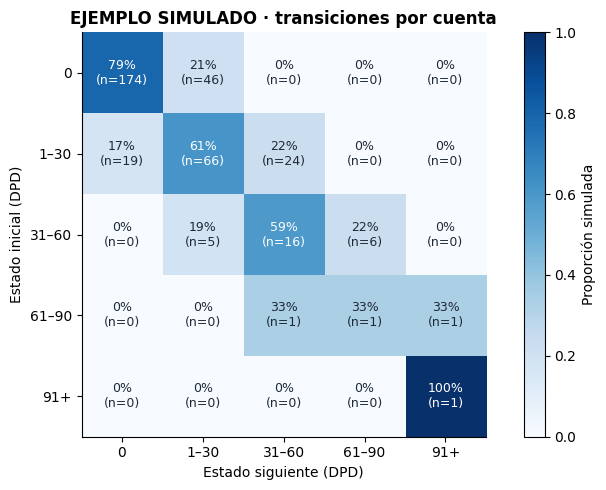

Datos simulados; pares: 360


In [5]:
rng=np.random.default_rng(20261112)
filas_demo=[]
for i in range(120):
    nivel=int(rng.choice([0,1,2],p=[.72,.21,.07]))
    for mob,fecha in enumerate(pd.date_range('2024-01-31',periods=4,freq='ME')):
        if mob: nivel=max(0,min(4,nivel+int(rng.choice([-1,0,1],p=[.16,.63,.21]))))
        filas_demo.append({'id_credito':f'SIM-{i:03d}','id_comercio':'SIM','mob':mob,'fecha_corte':fecha,'fecha_disponibilidad':fecha,'dias_mora':[0,15,45,75,105][nivel],'saldo_capital_cop':float(rng.integers(100_000,2_000_000))})
demo=pd.DataFrame(filas_demo);pares_demo,diag_demo=construir_pares(demo,'2024-05-01')
conteos_demo=pd.crosstab(pares_demo.estado,pares_demo.estado_siguiente).reindex(index=ESTADOS,columns=ESTADOS,fill_value=0)
prob_demo=conteos_demo.div(conteos_demo.sum(axis=1).replace(0,np.nan),axis=0)
fig,ax=plt.subplots(figsize=(8,5));cmap=plt.get_cmap('Blues').copy();cmap.set_bad('#e5e7eb');im=ax.imshow(prob_demo.to_numpy(dtype=float),vmin=0,vmax=1,cmap=cmap)
ax.set(xticks=range(5),yticks=range(5),xticklabels=ESTADOS,yticklabels=ESTADOS,xlabel='Estado siguiente (DPD)',ylabel='Estado inicial (DPD)',title='EJEMPLO SIMULADO · transiciones por cuenta')
for i in range(5):
    for j in range(5):
        v=prob_demo.iloc[i,j];ax.text(j,i,'—' if pd.isna(v) else f'{v:.0%}\n(n={conteos_demo.iloc[i,j]})',ha='center',va='center',color='white' if pd.notna(v) and v>.55 else '#1f2937',fontsize=9)
fig.colorbar(im,ax=ax,label='Proporción simulada');fig.tight_layout();plt.show()
print('Datos simulados; pares:',diag_demo['pares_consecutivos'])